In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C4"
DTYPE="LBP"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C4_10,25,"[DATA/TRAINING/C4/C4_10/IMG_6597.HEIC, DATA/TR..."
1,C4_11,27,"[DATA/TRAINING/C4/C4_11/IMG_6727.HEIC, DATA/TR..."
2,C4_12,27,"[DATA/TRAINING/C4/C4_12/IMG_6857.HEIC, DATA/TR..."
3,C4_13,30,"[DATA/TRAINING/C4/C4_13/IMG_6998.HEIC, DATA/TR..."
4,C4_14,27,"[DATA/TRAINING/C4/C4_14/IMG_7250.HEIC, DATA/TR..."
5,C4_15,25,"[DATA/TRAINING/C4/C4_15/IMG_7388.HEIC, DATA/TR..."
6,C4_16,28,"[DATA/TRAINING/C4/C4_16/IMG_7517.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16 %')

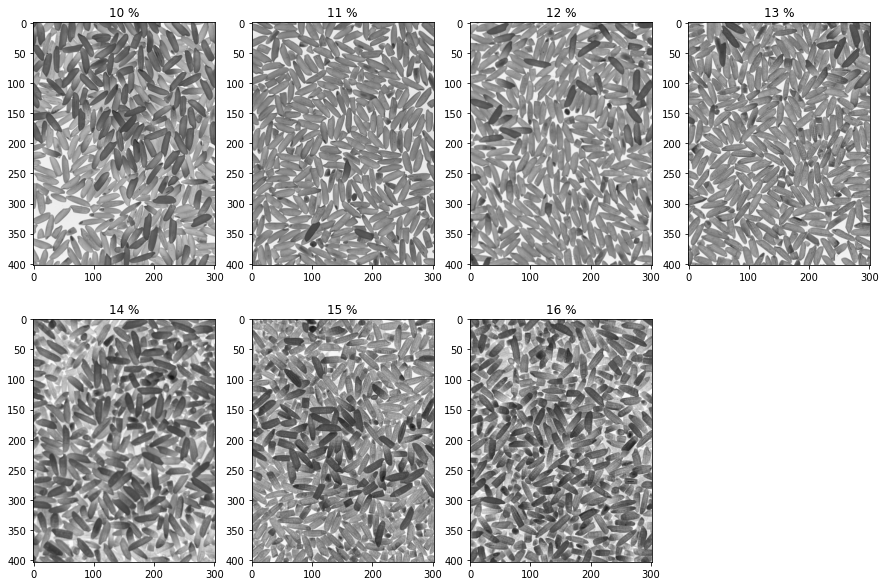

In [6]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1)
image = read_imgHEIC(data_path[0][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10 %")
ax2 = fig.add_subplot(2,4,2)
image = read_imgHEIC(data_path[1][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11 %")
ax3 = fig.add_subplot(2,4,3)
image = read_imgHEIC(data_path[2][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12 %")
ax4 = fig.add_subplot(2,4,4)
image = read_imgHEIC(data_path[3][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13 %")
ax5 = fig.add_subplot(2,4,5)
image = read_imgHEIC(data_path[4][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14 %")
ax6 = fig.add_subplot(2,4,6)
image = read_imgHEIC(data_path[5][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15 %")
ax7 = fig.add_subplot(2,4,7)
image = read_imgHEIC(data_path[6][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16 %")

In [7]:
def fd_gray(gray, bins, mask=None):
    # compute the gray color histogram
    hist  = cv2.calcHist([gray], [0], None, [bins], [0, 256])
    # normalize the histogram
    cv2.normalize(hist, hist)
    # return the histogram
    return hist, hist.flatten()

In [183]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        # Uniform LBP is used
        P=16; R=2
        lbp_ = local_binary_pattern(gray, P, R, method='uniform')
        n_bins = int(lbp_.max() + 1)
        hist_, bin_edges = np.histogram(lbp_.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        arr_img_hist.append(hist_)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["P"] = P
    pdGrayFeatures["R"] = R
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [184]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(P)+'_'+str(R)+'bins.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,16,17,scale,P,R,height,width,channels,IMAGENAME,HUMIDITY
0,0.094352,0.041204,0.045833,0.030926,0.017963,0.012685,0.011852,0.014722,0.022870,0.030556,...,0.085741,0.401111,3,16,2,120,90,3,IMG_6597.HEIC,10
1,0.088704,0.047222,0.043704,0.030185,0.020000,0.017407,0.013704,0.015093,0.024537,0.031389,...,0.086389,0.390926,3,16,2,120,90,3,IMG_6598.HEIC,10
2,0.082593,0.049815,0.041111,0.027870,0.019352,0.013704,0.014074,0.020926,0.029815,0.039167,...,0.082500,0.391574,3,16,2,120,90,3,IMG_6599.HEIC,10
3,0.091574,0.044630,0.045093,0.032870,0.021944,0.016852,0.011944,0.013519,0.022407,0.031481,...,0.087500,0.395833,3,16,2,120,90,3,IMG_6600.HEIC,10
4,0.091389,0.045185,0.042593,0.030648,0.024444,0.017037,0.015093,0.015278,0.023519,0.031111,...,0.087315,0.390833,3,16,2,120,90,3,IMG_6601.HEIC,10
5,0.091759,0.045463,0.045370,0.033889,0.020370,0.017870,0.015648,0.012963,0.020000,0.027315,...,0.091944,0.403889,3,16,2,120,90,3,IMG_6602.HEIC,10
6,0.092315,0.042315,0.046852,0.030185,0.022315,0.017593,0.016111,0.015648,0.025000,0.028611,...,0.088519,0.388056,3,16,2,120,90,3,IMG_6603.HEIC,10
7,0.090278,0.044074,0.047778,0.035648,0.023704,0.017037,0.015000,0.015648,0.022870,0.021019,...,0.096944,0.399352,3,16,2,120,90,3,IMG_6604.HEIC,10
8,0.096111,0.041204,0.045556,0.031111,0.024815,0.016389,0.014074,0.013519,0.015741,0.024259,...,0.098611,0.415463,3,16,2,120,90,3,IMG_6605.HEIC,10
9,0.089167,0.048241,0.045278,0.037222,0.022222,0.018981,0.013889,0.012963,0.017130,0.022130,...,0.093889,0.405185,3,16,2,120,90,3,IMG_6606.HEIC,10


# Classification

In [185]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-8]
#X

In [186]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [187]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [188]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [189]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [190]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.421053,0.428571,0.428571,0.428571,LBP,C4,RF_C,3,16,2,120,90,3
1,2,0.368421,0.345238,0.357143,0.351090,LBP,C4,RF_C,3,16,2,120,90,3
2,3,0.578947,0.595238,0.571429,0.583090,LBP,C4,RF_C,3,16,2,120,90,3
3,4,0.473684,0.571429,0.500000,0.533333,LBP,C4,RF_C,3,16,2,120,90,3
4,5,0.368421,0.341837,0.333333,0.337531,LBP,C4,RF_C,3,16,2,120,90,3
5,6,0.578947,0.571429,0.595238,0.583090,LBP,C4,RF_C,3,16,2,120,90,3
6,7,0.368421,0.571429,0.357143,0.439560,LBP,C4,RF_C,3,16,2,120,90,3
7,8,0.578947,0.728571,0.595238,0.655190,LBP,C4,RF_C,3,16,2,120,90,3
8,9,0.631579,0.700000,0.619048,0.657040,LBP,C4,RF_C,3,16,2,120,90,3
9,10,0.611111,0.702381,0.642857,0.671302,LBP,C4,RF_C,3,16,2,120,90,3


In [191]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C4,RF_C,0.497953,0.5,0.52398,0.555612


### MLP Classifier

In [192]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [193]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [194]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.578947,0.642857,0.595238,0.618132,LBP,C4,MLP_C,3,16,2,120,90,3
1,2,0.631579,0.652381,0.666667,0.659446,LBP,C4,MLP_C,3,16,2,120,90,3
2,3,0.315789,0.511905,0.309524,0.385783,LBP,C4,MLP_C,3,16,2,120,90,3
3,4,0.526316,0.452381,0.500000,0.475000,LBP,C4,MLP_C,3,16,2,120,90,3
4,5,0.421053,0.476190,0.428571,0.451128,LBP,C4,MLP_C,3,16,2,120,90,3
5,6,0.526316,0.521429,0.500000,0.510490,LBP,C4,MLP_C,3,16,2,120,90,3
6,7,0.368421,0.433333,0.357143,0.391566,LBP,C4,MLP_C,3,16,2,120,90,3
7,8,0.578947,0.805102,0.595238,0.684444,LBP,C4,MLP_C,3,16,2,120,90,3
8,9,0.368421,0.416667,0.357143,0.384615,LBP,C4,MLP_C,3,16,2,120,90,3
9,10,0.500000,0.678571,0.523810,0.591231,LBP,C4,MLP_C,3,16,2,120,90,3


In [195]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C4,MLP_C,0.481579,0.483333,0.515184,0.559082


### XGBoost Classifier

In [196]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [197]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.526316,0.538095,0.523810,0.530856,LBP,C4,XGB_C,3,16,2,120,90,3
1,2,0.368421,0.464286,0.357143,0.403727,LBP,C4,XGB_C,3,16,2,120,90,3
2,3,0.473684,0.511905,0.500000,0.505882,LBP,C4,XGB_C,3,16,2,120,90,3
3,4,0.526316,0.514286,0.523810,0.519004,LBP,C4,XGB_C,3,16,2,120,90,3
4,5,0.421053,0.559524,0.452381,0.500280,LBP,C4,XGB_C,3,16,2,120,90,3
5,6,0.368421,0.440476,0.357143,0.394456,LBP,C4,XGB_C,3,16,2,120,90,3
6,7,0.578947,0.580952,0.619048,0.599395,LBP,C4,XGB_C,3,16,2,120,90,3
7,8,0.368421,0.433333,0.380952,0.405458,LBP,C4,XGB_C,3,16,2,120,90,3
8,9,0.473684,0.476190,0.476190,0.476190,LBP,C4,XGB_C,3,16,2,120,90,3
9,10,0.444444,0.540476,0.452381,0.492520,LBP,C4,XGB_C,3,16,2,120,90,3


In [198]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C4,XGB_C,0.454971,0.464286,0.482777,0.505952


# External validation

In [199]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C4_10,5,"[DATA/TEST/C4/C4_10/IMG_6593.HEIC, DATA/TEST/C..."
1,C4_11,5,"[DATA/TEST/C4/C4_11/IMG_6718.HEIC, DATA/TEST/C..."
2,C4_12,5,"[DATA/TEST/C4/C4_12/IMG_6846.HEIC, DATA/TEST/C..."
3,C4_13,5,"[DATA/TEST/C4/C4_13/IMG_6983.HEIC, DATA/TEST/C..."
4,C4_14,5,"[DATA/TEST/C4/C4_14/IMG_7240.HEIC, DATA/TEST/C..."
5,C4_15,5,"[DATA/TEST/C4/C4_15/IMG_7378.HEIC, DATA/TEST/C..."
6,C4_16,5,"[DATA/TEST/C4/C4_16/IMG_7507.HEIC, DATA/TEST/C..."


In [200]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [201]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        # Uniform LBP is used
        P=16; R=2
        lbp_ = local_binary_pattern(gray, P, R, method='uniform')
        n_bins = int(lbp_.max() + 1)
        hist_, bin_edges = np.histogram(lbp_.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        arr_img_hist.append(hist_)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["P"] = P
    pdGrayFeatures["R"] = R
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [202]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(P)+'_'+str(R)+'bins.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,16,17,scale,P,R,height,width,channels,IMAGENAME,HUMIDITY
0,0.089630,0.045833,0.041574,0.030926,0.022130,0.017315,0.014722,0.018056,0.030093,0.037963,...,0.080648,0.371944,3,16,2,120,90,3,IMG_6593.HEIC,10
1,0.089815,0.043333,0.045833,0.029907,0.023426,0.014074,0.015278,0.014352,0.030093,0.036667,...,0.077130,0.374537,3,16,2,120,90,3,IMG_6594.HEIC,10
2,0.091204,0.042685,0.045000,0.029074,0.022037,0.016574,0.016296,0.016019,0.024167,0.032037,...,0.084907,0.386852,3,16,2,120,90,3,IMG_6595.HEIC,10
3,0.092870,0.043056,0.044537,0.034907,0.021204,0.015370,0.015556,0.016019,0.023241,0.027407,...,0.088426,0.387037,3,16,2,120,90,3,IMG_6596.HEIC,10
4,0.089167,0.048241,0.045278,0.037222,0.022222,0.018981,0.013889,0.012963,0.017130,0.022130,...,0.093889,0.405185,3,16,2,120,90,3,IMG_660.HEIC,10
0,0.091759,0.043796,0.042778,0.031296,0.022407,0.016852,0.015093,0.018056,0.028704,0.035648,...,0.078981,0.379444,3,16,2,120,90,3,IMG_6718.HEIC,11
1,0.089352,0.046944,0.038981,0.034167,0.020370,0.018426,0.017500,0.017222,0.027130,0.036111,...,0.077593,0.372037,3,16,2,120,90,3,IMG_6720.HEIC,11
2,0.096204,0.042593,0.042037,0.029537,0.020556,0.016204,0.014074,0.013148,0.021019,0.027778,...,0.091296,0.407778,3,16,2,120,90,3,IMG_6723.HEIC,11
3,0.097685,0.040556,0.041019,0.029074,0.020370,0.013241,0.014259,0.013148,0.020741,0.027315,...,0.090370,0.402870,3,16,2,120,90,3,IMG_6725.HEIC,11
4,0.097593,0.040093,0.041852,0.028333,0.020648,0.013704,0.014630,0.012870,0.020093,0.028148,...,0.091852,0.403333,3,16,2,120,90,3,IMG_6726.HEIC,11


In [203]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [204]:
X_test = dtFeaturesTest.values[:, :-8]
#X_test

In [205]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [206]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [207]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.50      0.40      0.44         5
     Class 1       0.33      0.40      0.36         5
     Class 2       0.75      0.60      0.67         5
     Class 3       0.17      0.20      0.18         5
     Class 4       0.67      0.40      0.50         5
     Class 5       0.50      0.40      0.44         5
     Class 6       0.50      0.80      0.62         5

    accuracy                           0.46        35
   macro avg       0.49      0.46      0.46        35
weighted avg       0.49      0.46      0.46        35



## MLP

In [208]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [209]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.20      0.20      0.20         5
     Class 1       0.50      0.20      0.29         5
     Class 2       0.50      0.60      0.55         5
     Class 3       0.20      0.20      0.20         5
     Class 4       0.50      0.20      0.29         5
     Class 5       0.38      0.60      0.46         5
     Class 6       0.71      1.00      0.83         5

    accuracy                           0.43        35
   macro avg       0.43      0.43      0.40        35
weighted avg       0.43      0.43      0.40        35



## XGBC

In [210]:
y_pred = modelXGBC.predict(X_test_scale) 

In [211]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.25      0.20      0.22         5
     Class 1       0.00      0.00      0.00         5
     Class 2       0.14      0.20      0.17         5
     Class 3       0.20      0.20      0.20         5
     Class 4       0.20      0.20      0.20         5
     Class 5       0.40      0.40      0.40         5
     Class 6       0.67      0.80      0.73         5

    accuracy                           0.29        35
   macro avg       0.27      0.29      0.27        35
weighted avg       0.27      0.29      0.27        35

